# 04 · Zero-grade cases and the absence effect (RQ4, RQ5)
**Study Smarter, Not Harder** · Member A (Data detective) · slide 6

A detective story in six stages: (1) a suspicious pattern, (2) the residual plot that exposes a cluster,
(3) a profile of the suspects with formal tests, (4) the before/after table, (5) an independent replication
in the maths file, and (6) robustness to how the zero-grade cases are treated.

*A word on language:* we call the 15 students with G3 = 0 **zero-grade cases** and, in the narrative, **apparent dropouts**.
The twist built on them is "The Perfect Attendance Paradox": zero recorded absences, yet a final grade of 0.
That is **our interpretation** of the data pattern (zero final grade, zero recorded absences, collapsing G2).
The UCI documentation does not say what happened to these students, so every key result is reported with
and without them.

Models (notebook 03 numbering): **M3** = G3 ~ studytime + academic/demographic + family/social controls; **M4** = M3 + G1 + G2. Robust (HC3) SEs for
inference; plain OLS residuals for Breusch-Pagan.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan

PROC = Path("../data/processed")
FIG = Path("../figures")
RES = Path("../results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"
sns.set_theme(style="whitegrid", context="talk", rc={"grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8",
                                                      "figure.dpi": 100, "savefig.dpi": 200})
pd.set_option("display.width", 140)

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved figures/" + name + ".png")

CONTROLS = ("failures + log_abs + C(sex) + C(school) + C(higher) + age + Medu + Fedu"
            " + goout + Dalc + Walc + freetime + health + C(internet) + C(schoolsup)"
            " + C(famsup) + C(paid) + C(romantic) + C(address)")
F_M3 = "G3 ~ studytime + " + CONTROLS
F_M4 = F_M3 + " + G1 + G2"

df = pd.read_csv(PROC / "student-por_clean.csv")
mat = pd.read_csv(PROC / "student-mat_clean.csv")
for d in (df, mat):
    d["zero_grade"] = d["zero_grade"].astype(bool)
nz = df[~df.zero_grade]
print("por:", df.shape, "zero-grade cases:", int(df.zero_grade.sum()), "| mat:", mat.shape, "zero-grade cases:", int(mat.zero_grade.sum()))

por: (649, 35) zero-grade cases: 15 | mat: (395, 35) zero-grade cases: 38


## Stage 1. The suspicious pattern
Absences should hurt grades. In the full Portuguese sample they barely seem to. Before any model, look at
**who has zero absences** at each final-grade level.

all     n=649: r(absences, G3) = -0.091 (p = 0.02)
G3 > 0  n=634: r(absences, G3) = -0.196 (p = 6.5e-07)
share with 0 absences, all students: 0.376
G3            0    1    5    6     7      8      9      10      11     12     13     14     15    16     17     18   19
n           15.0  1.0  1.0  3.0  10.0  35.00  35.00  97.00  104.00  72.00  82.00  63.00  49.00  36.0  29.00  15.00  2.0
share_abs0   1.0  1.0  0.0  0.0   0.2   0.17   0.29   0.31    0.28   0.36   0.48   0.38   0.39   0.5   0.45   0.73  0.5
saved figures/20_suspicious_pattern.png


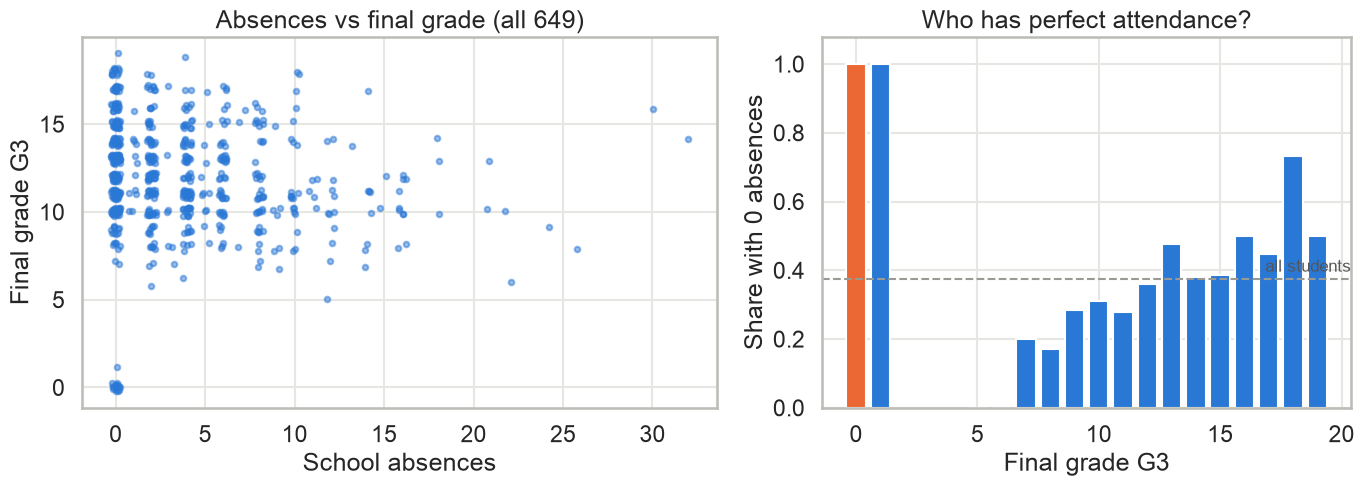

In [2]:
for label, d in [("all", df), ("G3 > 0", nz)]:
    r, p = stats.pearsonr(d.absences, d.G3)
    print(f"{label:7s} n={len(d)}: r(absences, G3) = {r:+.3f} (p = {p:.2g})")

share0 = df.groupby("G3").absences.agg(n="size", share_abs0=lambda s: (s == 0).mean())
print(f"share with 0 absences, all students: {(df.absences == 0).mean():.3f}")
print(share0.round(2).T)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
jit = np.random.default_rng(1).uniform(-0.25, 0.25, (2, len(df)))
ax.scatter(df.absences + jit[0], df.G3 + jit[1], s=16, alpha=0.5, color=BLUE)
ax.set(xlabel="School absences", ylabel="Final grade G3", title="Absences vs final grade (all 649)")
ax = axes[1]
cols = [ORANGE if g == 0 else BLUE for g in share0.index]
ax.bar(share0.index, share0.share_abs0, color=cols, width=0.8)
ax.axhline((df.absences == 0).mean(), color=GREY, ls="--", lw=1.5)
ax.text(20.4, (df.absences == 0).mean() + 0.02, "all students", ha="right", color="#555", fontsize=12)
ax.set(xlabel="Final grade G3", ylabel="Share with 0 absences", ylim=(0, 1.08),
       title="Who has perfect attendance?")
savefig(fig, "20_suspicious_pattern")

**Interpretation:** With everyone included, absences and G3 are only weakly related (r = -0.091, p = 0.02); among G3 > 0 students the correlation is about twice as strong (r = -0.196, p = 6.5e-7). The right panel is the clue: overall 37.6% of students have zero absences, and among passing students that share tends to rise with the grade (about 17-36% at G3 7-12, 38-73% at 13-18), yet **100% of the 15 students with G3 = 0** have zero absences. (The G3 = 1 bar is a single student, so it carries no weight.) The weakest students should have the most absences, not the fewest.

## Stage 2. The residual plot gives the cluster away
Fit M3 on all 649 students and plot residuals against fitted values and against log absences.

            count  mean   std    min    25%   50%   75%   max
zero_grade                                                   
False       634.0  0.22  2.20  -9.19  -1.28  0.08  1.56  7.37
True         15.0 -9.39  1.93 -12.22 -10.65 -9.28 -8.20 -5.41


zero-grade cases among the 20 most negative residuals: 15
saved figures/21_residuals_reveal_cluster.png


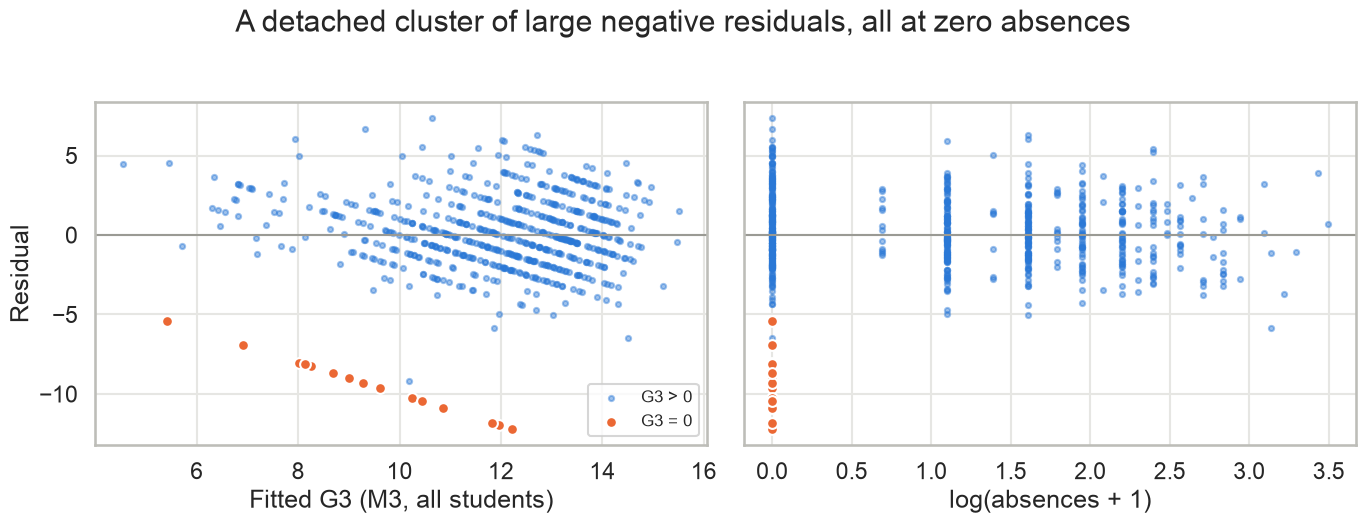

In [3]:
m3_all = smf.ols(F_M3, df).fit()
res = pd.DataFrame({"fitted": m3_all.fittedvalues, "resid": m3_all.resid, "zero_grade": df.zero_grade, "log_abs": df.log_abs})
print(res.groupby("zero_grade").resid.describe().round(2))
print("zero-grade cases among the 20 most negative residuals:", int(res.nsmallest(20, "resid").zero_grade.sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, x, xl in [(axes[0], "fitted", "Fitted G3 (M3, all students)"), (axes[1], "log_abs", "log(absences + 1)")]:
    g = res[~res.zero_grade]; h = res[res.zero_grade]
    ax.scatter(g[x], g.resid, s=14, alpha=0.45, color=BLUE, label="G3 > 0")
    ax.scatter(h[x], h.resid, s=60, color=ORANGE, edgecolor="white", lw=1.5, label="G3 = 0")
    ax.axhline(0, color=GREY, lw=1.5)
    ax.set(xlabel=xl)
axes[0].set_ylabel("Residual")
axes[0].legend(fontsize=12, loc="lower right")
fig.suptitle("A detached cluster of large negative residuals, all at zero absences", y=1.02)
savefig(fig, "21_residuals_reveal_cluster")

**Interpretation:** The M3 residuals of the 15 zero-grade cases range from -12.22 to -5.41 (mean -9.39), against a mean of +0.22 and SD 2.20 for everyone else, and all 15 are among the 20 most negative residuals. In the right panel they all sit at log(abs+1) = 0. The model is being asked to fit a group of zeros at the 'best attendance' end of the absence axis, which flattens the absence slope and inflates the residual variance there.

## Stage 3. Profile the suspects and test them

In [4]:
z = df[df.zero_grade]
cols = ["school", "sex", "age", "studytime", "failures", "higher", "absences", "G1", "G2", "G3"]
z[cols].sort_values(["G2", "G1"])

,school,sex,age,studytime,failures,higher,absences,G1,G2,G3
567,MS,M,18,1,1,no,0,4,0,0
603,MS,F,18,2,0,yes,0,5,0,0
605,MS,F,19,1,1,no,0,5,0,0
440,MS,M,16,2,0,yes,0,7,0,0
563,MS,M,17,1,1,yes,0,7,0,0
610,MS,F,19,2,3,no,0,8,0,0
597,MS,F,18,2,1,yes,0,9,0,0
626,MS,F,18,2,0,yes,0,7,5,0
583,MS,F,18,1,1,no,0,8,6,0
637,MS,M,18,1,0,yes,0,7,7,0


In [5]:
print(f"zero-grade cases: {len(z)}; absences == 0: {(z.absences == 0).sum()}; G2 == 0: {(z.G2 == 0).sum()}; "
      f"G1 == 0: {(z.G1 == 0).sum()}")
print("zero-grade cases by school:", z.school.value_counts().to_dict(), "| school sizes:", df.school.value_counts().to_dict())
gp = z[z.school == "GP"]
print("the GP zero-grade case:", gp[cols].to_dict("records"))
print("students with G3 > 0 with G2 == 0:", int((nz.G2 == 0).sum()), "| students with G3 > 0 with G2 <= 5:", int((nz.G2 <= 5).sum()))

# probability of 15/15 zero absences if zero-grade cases were a random draw from the population
p0 = (df.absences == 0).mean()
print(f"P(all 15 have 0 absences | random draw, p = {p0:.3f}) = {p0**15:.2e}")

ct = pd.crosstab(df.school, df.zero_grade)
print(ct)
odds, p = stats.fisher_exact(ct)
print(f"Fisher's exact (school x zero-grade): odds ratio = {odds:.1f}, p = {p:.2e}")
ct_abs = pd.crosstab(df.absences == 0, df.zero_grade)
print(f"Fisher's exact (zero absences x zero-grade): p = {stats.fisher_exact(ct_abs)[1]:.2e}")

rows = []
for v in ["G1", "G2", "failures", "studytime", "age", "absences"]:
    u = stats.mannwhitneyu(z[v], nz[v])
    rows.append({"variable": v, "zero_grade_mean": z[v].mean(), "other_mean": nz[v].mean(),
                 "MannWhitney_U": u.statistic, "p": u.pvalue})
for v, lev in [("higher", "yes"), ("sex", "F")]:
    t = pd.crosstab(df[v] == lev, df.zero_grade)
    rows.append({"variable": f"share {v}={lev}", "zero_grade_mean": (z[v] == lev).mean(),
                 "other_mean": (nz[v] == lev).mean(), "MannWhitney_U": np.nan,
                 "p": stats.fisher_exact(t)[1]})
prof = pd.DataFrame(rows).set_index("variable")
prof.round(4)

zero-grade cases: 15; absences == 0: 15; G2 == 0: 7; G1 == 0: 0
zero-grade cases by school: {'MS': 14, 'GP': 1} | school sizes: {'GP': 423, 'MS': 226}
the GP zero-grade case: [{'school': 'GP', 'sex': 'M', 'age': 18, 'studytime': 1, 'failures': 2, 'higher': 'no', 'absences': 0, 'G1': 11, 'G2': 9, 'G3': 0}]
students with G3 > 0 with G2 == 0: 0 | students with G3 > 0 with G2 <= 5: 2
P(all 15 have 0 absences | random draw, p = 0.376) = 4.24e-07
zero_grade  False  True 
school                  
GP            422      1
MS            212     14
Fisher's exact (school x zero-grade): odds ratio = 27.9, p = 3.04e-06
Fisher's exact (zero absences x zero-grade): p = 3.22e-07


,zero_grade_mean,other_mean,MannWhitney_U,p
variable,,,,
G1,7.0667,11.5016,779.5,0.0000
G2,3.8000,11.7539,224.0,0.0000
failures,0.8000,0.2082,6891.5,0.0000
studytime,1.4667,1.9416,3287.0,0.0273
age,17.8000,16.7192,7221.5,0.0004
absences,0.0000,3.7461,1717.5,0.0000
share higher=yes,0.6667,0.8991,NaN,0.0151
share sex=F,0.4667,0.5931,NaN,0.4268


               G1     G2  failures  absences
zero_grade                                  
False       10.53  10.96      0.29      2.79
True         6.79   3.43      0.71      0.00
MS students with G3 > 0 with 0 absences: 0.396


saved figures/22_zero_grade_trajectories.png


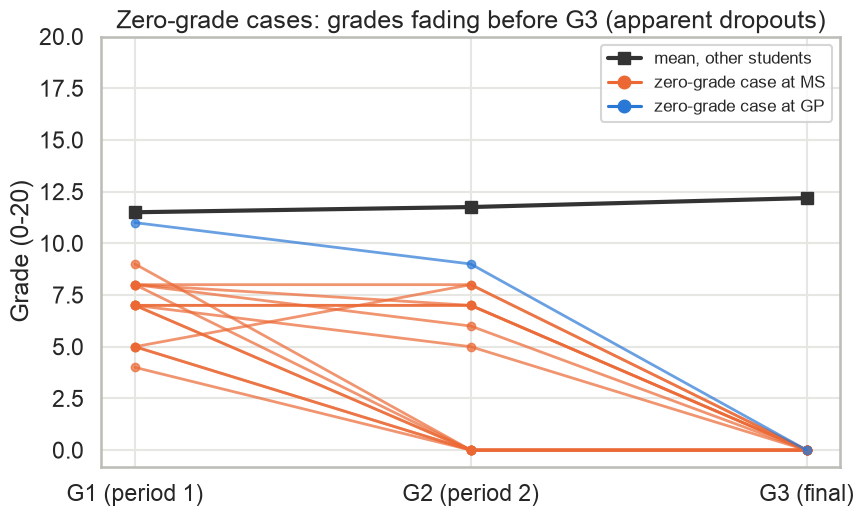

In [6]:
# within MS only: is the zero-grade profile just "MS students"?
ms = df[df.school == "MS"]
print(ms.groupby("zero_grade")[["G1", "G2", "failures", "absences"]].mean().round(2))
print(f"MS students with G3 > 0 with 0 absences: {(ms[~ms.zero_grade].absences == 0).mean():.3f}")

fig, ax = plt.subplots(figsize=(9, 5.5))
for i, (_, r) in enumerate(z.sort_values(["G2", "G1"]).iterrows()):
    ax.plot([1, 2, 3], [r.G1, r.G2, r.G3], "-o", color=ORANGE if r.school == "MS" else BLUE, alpha=0.7, lw=2, ms=6)
g = nz[["G1", "G2", "G3"]].mean()
ax.plot([1, 2, 3], g.values, "-s", color="#333", lw=3, ms=9, label="mean, other students")
ax.plot([], [], "-o", color=ORANGE, label="zero-grade case at MS"); ax.plot([], [], "-o", color=BLUE, label="zero-grade case at GP")
ax.set_xticks([1, 2, 3], ["G1 (period 1)", "G2 (period 2)", "G3 (final)"])
ax.set(ylabel="Grade (0-20)", title="Zero-grade cases: grades fading before G3 (apparent dropouts)", ylim=(-0.8, 20))
ax.legend(fontsize=12)
savefig(fig, "22_zero_grade_trajectories")

**Interpretation:** All 15 zero-grade cases have 0 absences (if 15 students were drawn at random, with 37.6% at zero absences, the chance of this is 4.2e-7; Fisher's exact on zero-absences x zero-grade, p = 3.2e-7). 14 of 15 are at MS (Fisher's exact on school, OR = 27.9, p = 3.0e-6). 7 of the 15 already had **G2 = 0** (no G3 > 0 student has G2 = 0), and the other 8 had G2 of 5-9; the single GP zero-grade case had G1 = 11 and G2 = 9, a middling student who then scored 0. Compared with students with G3 > 0, zero-grade cases had lower G1 (7.07 vs 11.50) and G2 (3.80 vs 11.75), more past failures (0.80 vs 0.21), lower study time (1.47 vs 1.94, p = 0.027), were older (17.8 vs 16.7), and fewer wanted higher education (67% vs 90%, p = 0.015); sex does not differ (p = 0.43). Within MS alone the same contrast holds, and 39.6% of MS students with G3 > 0 have 0 absences, so 'MS students just record no absences' does not explain why all 14 MS zero-grade cases have 0 absences. The trajectory plot shows students fading before the final grade. **This is consistent with dropping out (absence recording stopping when the student left), but dropout is our interpretation: the dataset does not record why G3 = 0.**

## Stage 4. Before / after: absences, correlation and Breusch-Pagan
Same models, with and without the 15 zero-grade cases.

In [7]:
def ba_row(d, label, extra=""):
    out = {"sample": label, "n": len(d)}
    r, p = stats.pearsonr(d.absences, d.G3)
    out.update(r_abs_G3=r, r_p=p)
    s = smf.ols("G3 ~ log_abs", d).fit(cov_type="HC3")
    out.update(logabs_simple=s.params["log_abs"], logabs_simple_p=s.pvalues["log_abs"])
    for name, f in [("M3", F_M3 + extra), ("M4", F_M4 + extra)]:
        ols = smf.ols(f, d).fit()
        rob = ols.get_robustcov_results(cov_type="HC3")
        i = ols.model.exog_names.index("log_abs")
        lm, lmp, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
        out.update({f"{name}_logabs": rob.params[i], f"{name}_logabs_p": rob.pvalues[i],
                    f"{name}_logabs_lo": rob.conf_int()[i][0], f"{name}_logabs_hi": rob.conf_int()[i][1],
                    f"{name}_studytime": rob.params[ols.model.exog_names.index("studytime")],
                    f"{name}_R2": ols.rsquared, f"{name}_BP_LM": lm, f"{name}_BP_p": lmp})
    return out

ba = pd.DataFrame([ba_row(df, "Portuguese, all"), ba_row(nz, "Portuguese, G3 > 0")]).set_index("sample")
ba.T.round(4)

sample,"Portuguese, all","Portuguese, G3 > 0"
n,649.0000,634.0000
r_abs_G3,-0.0914,-0.1960
r_p,0.0199,0.0000
logabs_simple,-0.2458,-0.5940
logabs_simple_p,0.0779,0.0000
M3_logabs,-0.1494,-0.4482
M3_logabs_p,0.2316,0.0000
M3_logabs_lo,-0.3944,-0.6527
M3_logabs_hi,0.0956,-0.2436
M3_studytime,0.4155,0.3104


In [8]:
# compact slide table
show = pd.DataFrame({
    "r(absences, G3)": ba.r_abs_G3.map("{:+.3f}".format) + " (p=" + ba.r_p.map("{:.2g}".format) + ")",
    "log_abs, simple": ba.logabs_simple.map("{:+.3f}".format) + " (p=" + ba.logabs_simple_p.map("{:.2g}".format) + ")",
    "log_abs in M3": ba.M3_logabs.map("{:+.3f}".format) + " (p=" + ba.M3_logabs_p.map("{:.2g}".format) + ")",
    "log_abs in M4": ba.M4_logabs.map("{:+.3f}".format) + " (p=" + ba.M4_logabs_p.map("{:.2g}".format) + ")",
    "BP on M3": "LM=" + ba.M3_BP_LM.map("{:.1f}".format) + " (p=" + ba.M3_BP_p.map("{:.2g}".format) + ")",
    "BP on M4": "LM=" + ba.M4_BP_LM.map("{:.1f}".format) + " (p=" + ba.M4_BP_p.map("{:.2g}".format) + ")",
}).T
show

sample,"Portuguese, all","Portuguese, G3 > 0"
"r(absences, G3)",-0.091 (p=0.02),-0.196 (p=6.5e-07)
"log_abs, simple",-0.246 (p=0.078),-0.594 (p=1e-07)
log_abs in M3,-0.149 (p=0.23),-0.448 (p=2e-05)
log_abs in M4,+0.159 (p=0.023),-0.008 (p=0.88)
BP on M3,LM=86.1 (p=3.5e-10),LM=24.2 (p=0.24)
BP on M4,LM=55.0 (p=0.00012),LM=39.7 (p=0.012)


saved figures/23_before_after_logabs.png


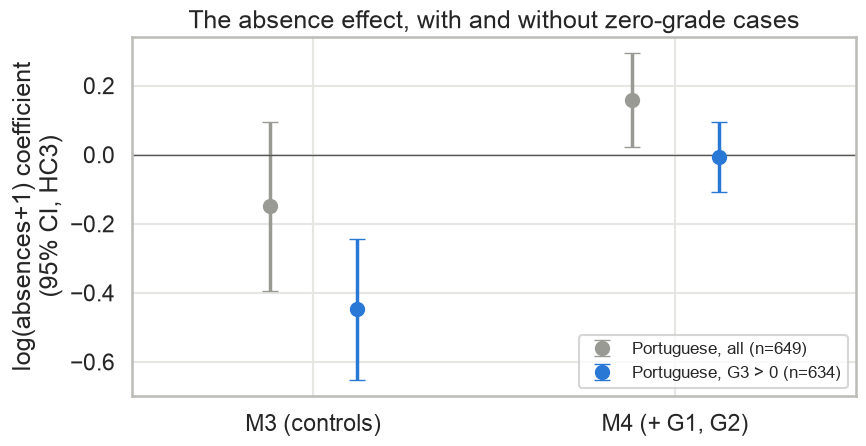

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
labels = ["M3 (controls)", "M4 (+ G1, G2)"]
for j, (samp, c, off) in enumerate([("Portuguese, all", GREY, -0.12), ("Portuguese, G3 > 0", BLUE, 0.12)]):
    r = ba.loc[samp]
    est = [r.M3_logabs, r.M4_logabs]
    lo = [r.M3_logabs_lo, r.M4_logabs_lo]; hi = [r.M3_logabs_hi, r.M4_logabs_hi]
    ax.errorbar(np.arange(2) + off, est, yerr=[np.subtract(est, lo), np.subtract(hi, est)], fmt="o", color=c,
                ms=10, lw=2.5, capsize=6, label=f"{samp} (n={int(r.n)})")
ax.axhline(0, color="#555", lw=1)
ax.set_xticks(range(2), labels)
ax.set(ylabel="log(absences+1) coefficient\n(95% CI, HC3)", title="The absence effect, with and without zero-grade cases",
       xlim=(-0.5, 1.5))
ax.legend(fontsize=12, loc="lower right")
savefig(fig, "23_before_after_logabs")

**Interpretation:** Removing the 15 zero-grade cases (2.3% of the sample) changes the absence story. In M3 the log-absence coefficient goes from -0.149 (p = 0.23, CI crosses 0) to **-0.448 (p = 2e-5, 95% CI -0.65 to -0.24)**. In M4 (with G1, G2) the misleading positive sign, +0.159 (p = 0.023), becomes -0.008 (p = 0.88): once earlier grades are known, absences add nothing, and the 'absences help' result was produced by the zero-grade cases. Breusch-Pagan on M3 goes from LM = 86.1 (p = 3.5e-10) to LM = 24.2 (p = 0.24). **Caveat not in the pilot:** on M4, Breusch-Pagan still rejects without the zero-grade cases (LM = 39.7, p = 0.012, down from 55.0, p = 0.0001), so the zero-grade cases explain the heteroskedasticity in M3 but not all of it in M4. HC3 standard errors remain the right default. The study-time coefficient in M3 moves from 0.416 to 0.310, so the zero-grade cases also inflated the study-time effect a little.

### Functional form for absences
`log_abs` vs `absences + I(absences**2)` vs linear `absences` in M3 (sample without zero-grade cases).

In [10]:
ff = []
for label, d in [("all", df), ("G3 > 0", nz)]:
    for form, term in [("log(abs+1)", "log_abs"), ("linear", "absences"), ("quadratic", "absences + I(absences**2)")]:
        m = smf.ols(F_M3.replace("log_abs", term), d).fit()
        ff.append({"sample": label, "form": form, "adj_R2": m.rsquared_adj, "AIC": m.aic})
pd.DataFrame(ff).pivot(index="form", columns="sample").round(3)

adj_R2              AIC          
sample     G3 > 0    all    G3 > 0       all
form                                        
linear      0.343  0.318  2808.985  3136.178
log(abs+1)  0.348  0.317  2804.199  3137.494
quadratic   0.347  0.317  2806.493  3138.163

**Interpretation:** Without the zero-grade cases, log(abs+1) fits best (lowest AIC 2804.2, adjusted R-squared 0.348), slightly ahead of the quadratic (2806.5) and linear (2809.0) forms. The differences are small (2-5 AIC points), so the choice of the log is reasonable but not decisive. With the zero-grade cases included, the three forms are indistinguishable (AIC 3136-3138), because the zero-grade cases swamp the absence signal.

## Stage 5. Independent replication: the maths file
The maths course (n = 395) is a separate set of grades (many students appear in both files, so it is not a
fully independent sample of *students*, but it is an independent set of *records*). Does the same pattern appear?

In [11]:
zm = mat[mat.zero_grade]; nzm = mat[~mat.zero_grade]
print(f"maths zero-grade cases: {len(zm)} of {len(mat)}; with absences == 0: {(zm.absences == 0).sum()} "
      f"(vs {(mat.absences == 0).mean():.3f} of all maths students)")
print(f"maths zero-grade cases: mean G1 = {zm.G1.mean():.2f}, mean G2 = {zm.G2.mean():.2f}, G2 == 0: {(zm.G2 == 0).sum()}")
print("maths zero-grade cases by school:", zm.school.value_counts().to_dict(), "| sizes:", mat.school.value_counts().to_dict())
ctm = pd.crosstab(mat.school, mat.zero_grade)
print("Fisher (school x zero-grade), maths:", stats.fisher_exact(ctm))

bam = pd.DataFrame([ba_row(mat, "Maths, all"), ba_row(nzm, "Maths, G3 > 0")]).set_index("sample")
ba_all = pd.concat([ba, bam])
bam.T.round(4)

maths zero-grade cases: 38 of 395; with absences == 0: 38 (vs 0.291 of all maths students)
maths zero-grade cases: mean G1 = 7.53, mean G2 = 4.66, G2 == 0: 13
maths zero-grade cases by school: {'GP': 34, 'MS': 4} | sizes: {'GP': 349, 'MS': 46}
Fisher (school x zero-grade), maths: SignificanceResult(statistic=np.float64(0.8823529411764706), pvalue=1.0)


sample,"Maths, all","Maths, G3 > 0"
n,395.0000,357.0000
r_abs_G3,0.0342,-0.2131
r_p,0.4973,0.0000
logabs_simple,0.7182,-0.7863
logabs_simple_p,0.0040,0.0000
M3_logabs,0.9845,-0.5490
M3_logabs_p,0.0001,0.0013
M3_logabs_lo,0.5014,-0.8817
M3_logabs_hi,1.4677,-0.2163
M3_studytime,0.5693,0.4345


saved figures/24_maths_replication.png


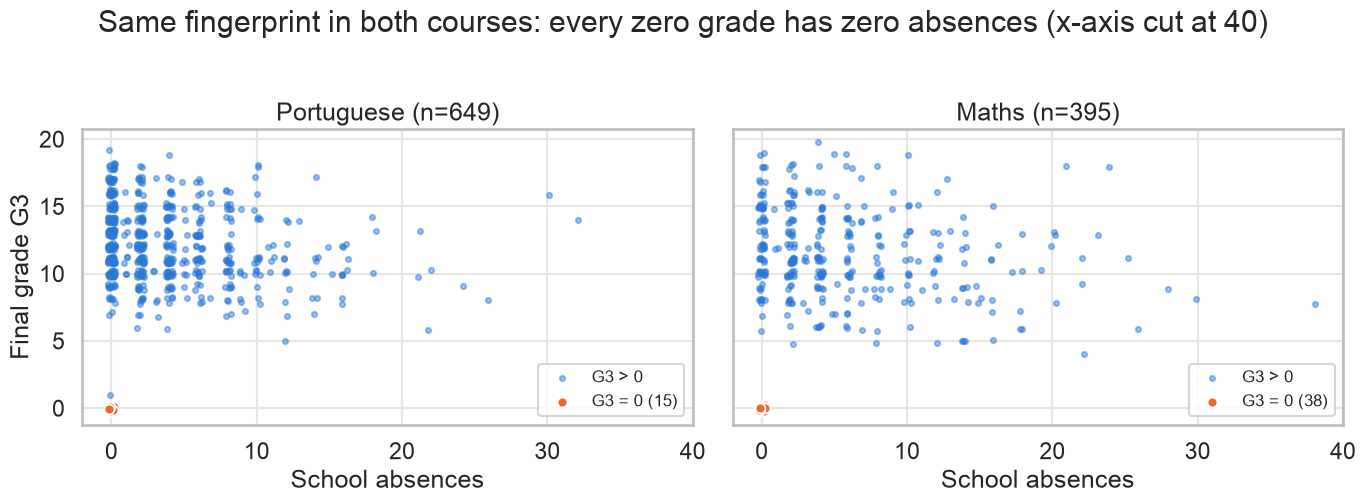

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, d, t in [(axes[0], df, "Portuguese (n=649)"), (axes[1], mat, "Maths (n=395)")]:
    jit = np.random.default_rng(2).uniform(-0.25, 0.25, (2, len(d)))
    g = ~d.zero_grade.values
    ax.scatter(d.absences[g] + jit[0][g], d.G3[g] + jit[1][g], s=14, alpha=0.45, color=BLUE, label="G3 > 0")
    ax.scatter(d.absences[~g] + jit[0][~g], d.G3[~g] + jit[1][~g], s=50, color=ORANGE, edgecolor="white", lw=1.2,
               label=f"G3 = 0 ({int(d.zero_grade.sum())})")
    ax.set(xlabel="School absences", title=t, xlim=(-2, 40))
    ax.legend(fontsize=12, loc="lower right")
axes[0].set_ylabel("Final grade G3")
fig.suptitle("Same fingerprint in both courses: every zero grade has zero absences (x-axis cut at 40)", y=1.02)
savefig(fig, "24_maths_replication")

**Interpretation:** **The core fingerprint replicates:** all 38 maths zeros have 0 absences (vs 29.1% of all maths students), their mean G2 is 4.66, and 13 of them have G2 = 0. The distortion is even larger in maths: with the zero-grade cases, the log-absence coefficient in M3 is **positive and significant (+0.98, p = 0.0001)**, and it becomes -0.55 (p = 0.001) without them. In M4 it goes from +0.63 (p < 1e-4) to -0.05 (p = 0.30). Breusch-Pagan on M3 goes from LM = 57.9 (p < 1e-6) to 26.7 (p = 0.14). **The school pattern does not replicate:** in maths, 34 of 38 zero-grade cases are at GP, in line with school size (GP 349, MS 46; Fisher p = 1.0). So the 'one school' fact in the Portuguese file is not a general feature of the zero-grade cases and should not carry the story. The zero-absence, collapsing-G2 signature does. (Many students appear in both files, so this is a replication on a second set of course records, not on a new set of students.)

## Stage 6. Robustness: does the conclusion depend on how we treat the zero-grade cases?
Three alternative treatments of the 15 zeros, compared with keeping them as ordinary observations:
(a) drop them (G3 > 0), (b) keep them with a zero-grade dummy, (c) restrict to students with G2 > 0
(i.e. drop students who had already vanished by period 2; this also drops students with G3 > 0 with G2 = 0, if any).

In [13]:
def key_coefs(d, label, extra=""):
    out = {"treatment": label, "n": len(d)}
    for name, f in [("M3", F_M3 + extra), ("M4", F_M4 + extra)]:
        m = smf.ols(f, d).fit(cov_type="HC3")
        for v in ["log_abs", "studytime"]:
            out[f"{name}_{v}"] = m.params[v]; out[f"{name}_{v}_p"] = m.pvalues[v]
    return out

dfd = df.assign(zero_grade_d=df.zero_grade.astype(int))
rob = pd.DataFrame([
    key_coefs(df, "keep zero-grade cases as-is"),
    key_coefs(nz, "(a) drop zero-grade cases (G3 > 0)"),
    key_coefs(dfd, "(b) zero-grade dummy", extra=" + zero_grade_d"),
    key_coefs(df[df.G2 > 0], "(c) restrict to G2 > 0"),
]).set_index("treatment")
rob.round(4)

,n,M3_log_abs,M3_log_abs_p,M3_studytime,M3_studytime_p,M4_log_abs,M4_log_abs_p,M4_studytime,M4_studytime_p
treatment,,,,,,,,,
keep zero-grade cases as-is,649,-0.1494,0.2311,0.4155,0.0010,0.1585,0.0224,0.0534,0.3070
(a) drop zero-grade cases (G3 > 0),634,-0.4482,0.0000,0.3104,0.0088,-0.0077,0.8813,0.0143,0.7470
(b) zero-grade dummy,649,-0.4652,0.0000,0.3146,0.0079,-0.0254,0.6256,0.0267,0.5584
(c) restrict to G2 > 0,642,-0.2796,0.0187,0.3961,0.0014,0.1456,0.0512,0.0549,0.2889


**Interpretation:** The M3 conclusion is robust: log absences have a negative, significant association whenever the zero-grade cases are handled in any way, whether dropped (-0.448, p < 1e-4), absorbed by a zero-grade dummy (-0.465, p < 1e-4), or partly removed by restricting to G2 > 0 (-0.280, p = 0.019). The G2 > 0 restriction removes only the 7 zero-grade cases who had G2 = 0, so it is a partial fix, and the estimate falls between the two other treatments. In M4 the 'absences help' sign appears only when zero-grade cases remain in the sample as ordinary observations (+0.159, p = 0.022; +0.146, p = 0.051 under G2 > 0, where 8 zero-grade cases remain) and disappears under the drop or dummy treatments (-0.008 and -0.025, both n.s.). Study time's M3 coefficient stays positive and significant in all four (0.31-0.42, p <= 0.009) and its M4 coefficient stays non-significant in all four, so the coefficient-ladder story does not depend on how zero-grade cases are handled.

## Outputs

In [14]:
out = ba_all.copy()
out.to_csv(RES / "zero_grade_before_after.csv")
rob.to_csv(RES / "zero_grade_robustness.csv")
print("saved results/zero_grade_before_after.csv and results/zero_grade_robustness.csv")
print(out.round(4).T)

saved results/zero_grade_before_after.csv and results/zero_grade_robustness.csv
sample           Portuguese, all  Portuguese, G3 > 0  Maths, all  Maths, G3 > 0
n                       649.0000            634.0000    395.0000       357.0000
r_abs_G3                 -0.0914             -0.1960      0.0342        -0.2131
r_p                       0.0199              0.0000      0.4973         0.0000
logabs_simple            -0.2458             -0.5940      0.7182        -0.7863
logabs_simple_p           0.0779              0.0000      0.0040         0.0000
M3_logabs                -0.1494             -0.4482      0.9845        -0.5490
M3_logabs_p               0.2316              0.0000      0.0001         0.0013
M3_logabs_lo             -0.3944             -0.6527      0.5014        -0.8817
M3_logabs_hi              0.0956             -0.2436      1.4677        -0.2163
M3_studytime              0.4155              0.3104      0.5693         0.4345
M3_R2                     0.3377        

## Pilot check (readme section 5)
Automatic comparison with the pilot numbers. Any `False` is flagged in the summary below.

In [15]:
P, N = ba.loc["Portuguese, all"], ba.loc["Portuguese, G3 > 0"]
checks = {
    "zero-grade cases (15)": (len(z), 15),
    "zero-grade cases with 0 absences (15)": ((z.absences == 0).sum(), 15),
    "zero-grade cases at MS (14)": ((z.school == "MS").sum(), 14),
    "zero-grade mean G1 (7.1)": (z.G1.mean(), 7.1),
    "zero-grade mean G2 (3.8)": (z.G2.mean(), 3.8),
    "r(abs,G3) all (-0.09)": (P.r_abs_G3, -0.09),
    "r(abs,G3) G3>0 (-0.20)": (N.r_abs_G3, -0.20),
    "log_abs simple all (-0.25)": (P.logabs_simple, -0.25),
    "log_abs simple G3>0 (-0.59)": (N.logabs_simple, -0.59),
    "log_abs M3 all (-0.15)": (P.M3_logabs, -0.15),
    "log_abs M3 G3>0 (-0.45)": (N.M3_logabs, -0.45),
    "log_abs M4 all (+0.16)": (P.M4_logabs, 0.16),
    "log_abs M4 G3>0 (-0.01)": (N.M4_logabs, -0.01),
    "BP LM M3 all (86.1)": (P.M3_BP_LM, 86.1),
    "BP LM M3 G3>0 (24.2)": (N.M3_BP_LM, 24.2),
    "BP p M3 G3>0 (0.24)": (N.M3_BP_p, 0.24),
    "maths zero-grade cases (38)": (len(zm), 38),
    "maths zero-grade cases 0 absences (38)": ((zm.absences == 0).sum(), 38),
}
chk = pd.DataFrame([{"check": k, "notebook": round(float(v), 3), "pilot": p,
                     "match": abs(float(v) - p) <= 0.006 + 0.01 * abs(p)} for k, (v, p) in checks.items()])
print("all match:", chk.match.all())
chk

all match: True


,check,notebook,pilot,match
0,zero-grade cases (15),15.000,15.00,True
1,zero-grade cases with 0 absences (15),15.000,15.00,True
2,zero-grade cases at MS (14),14.000,14.00,True
3,zero-grade mean G1 (7.1),7.067,7.10,True
4,zero-grade mean G2 (3.8),3.800,3.80,True
5,"r(abs,G3) all (-0.09)",-0.091,-0.09,True
6,"r(abs,G3) G3>0 (-0.20)",-0.196,-0.20,True
7,log_abs simple all (-0.25),-0.246,-0.25,True
8,log_abs simple G3>0 (-0.59),-0.594,-0.59,True
9,log_abs M3 all (-0.15),-0.149,-0.15,True


## Summary

- **Pilot check:** every zero-grade and before/after number in readme section 5 is reproduced (18/18 checks within rounding).
- **The story holds:** 15 G3 = 0 students, all with 0 absences, 14/15 at MS, 7 with G2 = 0. Dropping them turns the M3 log-absence effect from -0.15 (n.s.) into -0.45 (p = 2e-5) and removes M3's heteroskedasticity (BP p from 3.5e-10 to 0.24). The 'absences help' result in M4 (+0.16, p = 0.02) is caused by the zero-grade cases.
- **New, not in the readme (flag for slides):** (1) Breusch-Pagan on **M4** still rejects without zero-grade cases (p = 0.012), so 'the heteroskedasticity goes away' is true for M3 only. (2) In maths the zero-grade cases are 34/38 at **GP**, so the school concentration does **not** replicate; the zero-absence signature does, and the maths distortion is even bigger (log-absence +0.98, p = 0.0001 with zero-grade cases; -0.55, p = 0.001 without). (3) Zero-grade cases also report less study time and less wish for higher education.
- **Robustness:** the M3 absence conclusion and the study-time ladder hold under dropping, a zero-grade dummy, or restricting to G2 > 0.
- **Interpretation caveat:** 'dropout' is our reading of the pattern, not something the data documents.